# 3. Within cities: does the national pattern hold inside Metro Manila, Metro Cebu and Metro Davao?

**Question.** Inside a city, rich and poor neighbourhoods sit side by side, and outlets are common. Does the national association between wealth and outlet density appear inside the three largest metropolitan areas too (RQ3)?

**The three cities.** Each is defined from an official source, and `src/shared/common.py` holds the lists:

- **Metro Manila.** The National Capital Region (NCR): its 17 cities and municipality.
- **Metro Cebu.** The 13 cities and municipalities of the Metro Cebu Development and Coordinating Board (MCDCB), set up by a memorandum of agreement on 1 April 2011, as listed in the JICA-MCDCB *Roadmap Study for Sustainable Urban Development in Metro Cebu* (final report, June 2015): the cities of Cebu, Lapu-Lapu, Mandaue, Talisay, Danao, Carcar and Naga, and Compostela, Consolacion, Cordova, Liloan, Minglanilla and San Fernando. No statute defines Metro Cebu.
- **Metro Davao.** The 15 cities and municipalities of Republic Act No. 11708, the Metropolitan Davao Development Authority Act (approved 13 April 2022), Section 4: Davao City; Panabo, Tagum and the Island Garden City of Samal, with Carmen (Davao del Norte); Digos, with Santa Cruz, Hagonoy, Padada, Malalag and Sulop (Davao del Sur); Mati (Davao Oriental); Maco (Davao de Oro); and Malita and Santa Maria (Davao Occidental).

Metro Davao is far larger than the other two: Davao City alone covers about 2,400 km², much of it rural uplands, and the metro reaches Mati and Malita, so it holds a wider spread of urban and rural places than Metro Manila does.

**Unit.** The barangay. A city has too few RWI tiles, and they are too coarse, to compare its neighbourhoods, so the tile version is run as a low-n check.

**Model.** The same NB2 count models, presence models and spatial checks as notebook 2, with these changes:

- **Intercepts.** City and municipality intercepts instead of province intercepts (the tile check keeps province intercepts: NCR's four districts, Cebu's one province, Metro Davao's five).
- **Errors.** Clustered by the RWI tile each barangay's people mostly live in, since several barangays share one tile's wealth value.
- **Wealth unit.** Still one *national* tile SD, so every city's ratios read on the same scale as the national ones.
- **Thin data.** A model is reported as not estimable, with its numbers, rather than forced: a count model needs at least 20 units with an outlet, a presence model at least 20 units with and 20 without, and a presence fit whose controls separate the two groups so completely that the wealth error collapses is dropped.

In [1]:
import sys
from pathlib import Path

# The notebooks import their logic from src/: the shared helpers and the analysis functions.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shared").is_dir())
for folder in ("src/shared", "src/03_analyse"):
    sys.path.insert(0, str(ROOT / folder))

import pandas as pd
from IPython.display import Image

from analysis_samples import RWI_SD, TABLES

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

import charts
import count_models as cm

## The three samples

In [2]:
from analysis_samples import BARANGAYS, CITIES, TILES, city

rows = []
for scope in CITIES:
    b, t = city(BARANGAYS, scope), city(TILES, scope)
    rows.append({"city": scope, "LGUs": b.adm3_pcode.nunique(), "barangays": len(b), "people": int(b["pop"].sum()),
                 "outlets": int(b.outlets.sum()), "barangays with an outlet": int(b.any_outlet.sum()),
                 "RWI tiles (clusters)": b.main_tile.nunique(), "outlets per 100,000": round(b.outlets.sum() / b["pop"].sum() * 1e5, 1),
                 "SD of RWI (barangays)": round(b.rwi.std(), 3), "tiles": len(t), "tiles with an outlet": int(t.any_outlet.sum())})
pd.DataFrame(rows).set_index("city").T

city,NCR,Metro Cebu,Metro Davao
LGUs,1.700000e+01,13.000,15.000
barangays,1.711000e+03,348.000,548.000
people,1.401619e+07,3204983.000,3444878.000
outlets,1.979000e+03,239.000,188.000
barangays with an outlet,6.860000e+02,120.000,90.000
RWI tiles (clusters),1.130000e+02,172.000,420.000
"outlets per 100,000",1.410000e+01,7.500,5.500
SD of RWI (barangays),2.040000e-01,0.573,0.644
tiles,1.210000e+02,217.000,913.000
tiles with an outlet,1.140000e+02,54.000,64.000


**Reading.** Metro Cebu and Metro Davao each hold about 3.2 to 3.4 million people, a quarter of NCR's 14.0 million, with far fewer outlets (239 and 188 against 1,979) and lower rates (7.5 and 5.5 per 100,000 against 14.1).
Both still have enough for every model: 120 and 90 barangays with an outlet, in 172 and 420 RWI tiles (the error clusters).
Their wealth spread is much wider than NCR's: the SD of barangay RWI is 0.57 in Metro Cebu and 0.64 in Metro Davao, against 0.20 in NCR, and one national SD is 0.49.
So a one-SD contrast compares neighbourhoods that exist side by side in Cebu and Davao, while in NCR it reaches beyond the region's own range.

## NCR barangays

In [3]:
ncr_barangays = cm.fit_scope("ncr_barangays")

NCR barangays: 1,711 units, 1,979 outlets, 686 units with one
  count wealth only        rate ratio 0.948 (0.823-1.092)
  count + urban share      rate ratio 0.947 (0.822-1.090)
  spatial refit (25 eigenvectors) rate ratio 1.042 (0.878-1.237); residual Moran's I 0.0490 -> 0.0236
  count + shops            rate ratio 0.887 (0.753-1.044)
  spatial refit (25 eigenvectors) rate ratio 0.918 (0.754-1.118); residual Moran's I 0.0467 -> 0.0231
  count + shops and roads  rate ratio 0.934 (0.826-1.056)
  presence + urban share   odds ratio 1.202 (0.896-1.612) [9 units in areas with no variation dropped; 0 fitted at 0 or 1]
  presence + shops         odds ratio 1.225 (0.847-1.771) [9 units in areas with no variation dropped; 0 fitted at 0 or 1]
  LISA clusters: {'Not significant': 1509, 'Low-High': 73, 'Low-Low': 53, 'High-High': 48, 'High-Low': 28}


In [4]:
cm.summary(ncr_barangays)

,scope,unit,model,variant,estimate,n,wealth_ratio,ci_low,ci_high,p_value
0,NCR,barangay,count,wealth only,rate ratio,1711,0.948,0.823,1.092,0.4573
1,NCR,barangay,count,+ urban share,rate ratio,1711,0.947,0.822,1.090,0.4494
2,NCR,barangay,"count, spatial refit",+ urban share,rate ratio,1711,1.042,0.878,1.237,0.6370
3,NCR,barangay,count,+ shops,rate ratio,1711,0.887,0.753,1.044,0.1483
4,NCR,barangay,"count, spatial refit",+ shops,rate ratio,1711,0.918,0.754,1.118,0.3940
5,NCR,barangay,count,+ shops and roads,rate ratio,1711,0.934,0.826,1.056,0.2776
6,NCR,barangay,presence,+ urban share,odds ratio,1702,1.202,0.896,1.612,0.2190
7,NCR,barangay,presence,+ shops,odds ratio,1702,1.225,0.847,1.771,0.2814


**Reading.** Inside NCR there is no clear wealth gradient.
The rate ratio is 0.95 (0.82-1.09) without shops and 0.89 (0.75-1.04) with them, and every interval includes 1.
The presence odds ratios (about 1.2) are also inside noise.
Residuals cluster mildly (Moran's I about 0.05); a 25-eigenvector refit halves that and gives 1.04 and 0.92, still with intervals across 1.

## NCR tiles (low-n check)

In [5]:
ncr_tiles = cm.fit_scope("ncr_tiles")

NCR tiles: 121 units, 1,963 outlets, 114 units with one
  count wealth only        rate ratio 0.965 (0.839-1.111)
  count + urban share      rate ratio 0.950 (0.826-1.092)
  count + shops            rate ratio 0.921 (0.818-1.037)
  count + shops and roads  rate ratio 0.941 (0.841-1.053)
  presence model not estimable: 114 of 121 units have an outlet


In [6]:
cm.summary(ncr_tiles)

,scope,unit,model,variant,estimate,n,wealth_ratio,ci_low,ci_high,p_value
0,NCR,tile,count,wealth only,rate ratio,121,0.965,0.839,1.111,0.6214
1,NCR,tile,count,+ urban share,rate ratio,121,0.950,0.826,1.092,0.4714
2,NCR,tile,count,+ shops,rate ratio,121,0.921,0.818,1.037,0.1719
3,NCR,tile,count,+ shops and roads,rate ratio,121,0.941,0.841,1.053,0.2870


**Reading.** The 121 NCR tiles agree with the barangays: 0.95 without shops and 0.92 with them, both with intervals across 1.
The presence model cannot be estimated, because 114 of the 121 tiles have an outlet.

## Metro Cebu barangays

In [7]:
cebu_barangays = cm.fit_scope("cebu_barangays")

Metro Cebu barangays: 348 units, 239 outlets, 120 units with one
  count wealth only        rate ratio 3.326 (2.085-5.306)
  count + urban share      rate ratio 2.341 (1.391-3.939)
  spatial refit (10 eigenvectors) rate ratio 2.286 (1.228-4.258); residual Moran's I 0.0774 -> -0.0048
  count + shops            rate ratio 1.230 (0.648-2.335)
  spatial refit (10 eigenvectors) rate ratio 1.409 (0.753-2.637); residual Moran's I 0.0991 -> -0.0188
  count + shops and roads  rate ratio 1.163 (0.715-1.891)
  presence + urban share   odds ratio 3.510 (1.709-7.212) [0 units in areas with no variation dropped; 35 fitted at 0 or 1]
  presence + shops         odds ratio 1.065 (0.432-2.629) [0 units in areas with no variation dropped; 22 fitted at 0 or 1]
  LISA clusters: {'Not significant': 314, 'High-High': 14, 'Low-Low': 9, 'High-Low': 5, 'Low-High': 4, 'No neighbours': 2}


In [8]:
cm.summary(cebu_barangays)

,scope,unit,model,variant,estimate,n,wealth_ratio,ci_low,ci_high,p_value
0,Metro Cebu,barangay,count,wealth only,rate ratio,348,3.326,2.085,5.306,0.0000
1,Metro Cebu,barangay,count,+ urban share,rate ratio,348,2.341,1.391,3.939,0.0014
2,Metro Cebu,barangay,"count, spatial refit",+ urban share,rate ratio,348,2.286,1.228,4.258,0.0092
3,Metro Cebu,barangay,count,+ shops,rate ratio,348,1.230,0.648,2.335,0.5275
4,Metro Cebu,barangay,"count, spatial refit",+ shops,rate ratio,348,1.409,0.753,2.637,0.2834
5,Metro Cebu,barangay,count,+ shops and roads,rate ratio,348,1.163,0.715,1.891,0.5429
6,Metro Cebu,barangay,presence,+ urban share,odds ratio,348,3.510,1.709,7.212,0.0006
7,Metro Cebu,barangay,presence,+ shops,odds ratio,348,1.065,0.432,2.629,0.8908


**Reading.** Inside Metro Cebu, richer barangays have more outlets per person before shops are controlled for: 3.33 (2.09-5.31) on wealth alone and 2.34 (1.39-3.94) with urban share.
With shops the ratio falls to 1.23 (0.65-2.33), and with shops and roads to 1.16 (0.72-1.89), both with intervals across 1.
So the gradient inside Metro Cebu goes with where shops are: among barangays with the same amount of retail, richer and poorer ones have outlet densities that cannot be told apart.
Residuals cluster (Moran's I 0.08 without shops and 0.10 with them); a 10-eigenvector refit removes the clustering and gives 2.29 and 1.41, the same story.
The presence model agrees, at 3.51 (1.71-7.21) without shops and 1.07 (0.43-2.63) with them.
It is the weaker of the two models here, though: 35 (and, with shops, 22) of the 348 barangays are fitted at a probability of 0 or 1.
These are small, mostly rural barangays with no outlet, so the odds ratios rest on the rest.

## Metro Cebu tiles (low-n check)

In [9]:
cebu_tiles = cm.fit_scope("cebu_tiles")

Metro Cebu tiles: 217 units, 239 outlets, 54 units with one
  count wealth only        rate ratio 2.357 (1.825-3.046)
  count + urban share      rate ratio 1.743 (1.368-2.222)
  count + shops            rate ratio 0.911 (0.737-1.126)
  count + shops and roads  rate ratio 0.951 (0.776-1.167)
  presence + urban share   not estimable: complete or quasi-complete separation, 96 of 217 units fitted at a probability of 0 or 1
  presence + shops         not estimable: complete or quasi-complete separation, 80 of 217 units fitted at a probability of 0 or 1


In [10]:
cm.summary(cebu_tiles)

,scope,unit,model,variant,estimate,n,wealth_ratio,ci_low,ci_high,p_value
0,Metro Cebu,tile,count,wealth only,rate ratio,217,2.357,1.825,3.046,0.0000
1,Metro Cebu,tile,count,+ urban share,rate ratio,217,1.743,1.368,2.222,0.0000
2,Metro Cebu,tile,count,+ shops,rate ratio,217,0.911,0.737,1.126,0.3890
3,Metro Cebu,tile,count,+ shops and roads,rate ratio,217,0.951,0.776,1.167,0.6323


**Reading.** The 217 Metro Cebu tiles agree with the barangays: 1.74 (1.37-2.22) without shops and 0.91 (0.74-1.13) with them.
The presence model cannot be estimated on tiles: urban share separates tiles with and without an outlet almost completely (96 of the 217 tiles are fitted at a probability of 0 or 1), and the wealth error collapses, so no presence ratio is reported.

## Metro Davao barangays

In [11]:
davao_barangays = cm.fit_scope("davao_barangays")

Metro Davao barangays: 548 units, 188 outlets, 90 units with one
  count wealth only        rate ratio 4.652 (2.908-7.442)
  count + urban share      rate ratio 4.552 (2.590-8.000)
  count + shops            rate ratio 3.475 (1.675-7.209)
  count + shops and roads  rate ratio 1.967 (1.203-3.214)
  presence + urban share   odds ratio 7.095 (3.712-13.560) [54 units in areas with no variation dropped; 0 fitted at 0 or 1]
  presence + shops         odds ratio 3.348 (1.442-7.776) [54 units in areas with no variation dropped; 0 fitted at 0 or 1]
  LISA clusters: {'Not significant': 493, 'Low-Low': 20, 'Low-High': 19, 'High-High': 10, 'High-Low': 6}


In [12]:
cm.summary(davao_barangays)

,scope,unit,model,variant,estimate,n,wealth_ratio,ci_low,ci_high,p_value
0,Metro Davao,barangay,count,wealth only,rate ratio,548,4.652,2.908,7.442,0.0000
1,Metro Davao,barangay,count,+ urban share,rate ratio,548,4.552,2.590,8.000,0.0000
2,Metro Davao,barangay,count,+ shops,rate ratio,548,3.475,1.675,7.209,0.0008
3,Metro Davao,barangay,count,+ shops and roads,rate ratio,548,1.967,1.203,3.214,0.0070
4,Metro Davao,barangay,presence,+ urban share,odds ratio,494,7.095,3.712,13.560,0.0000
5,Metro Davao,barangay,presence,+ shops,odds ratio,494,3.348,1.442,7.776,0.0049


**Reading.** Metro Davao shows the steepest gradient of the three cities, and it holds with every control.
The rate ratio is 4.55 (2.59-8.00) with urban share and 3.47 (1.68-7.21) with shops; adding road length brings it to 1.97 (1.20-3.21), still above 1.
The presence model agrees: 7.09 (3.71-13.56) without shops and 3.35 (1.44-7.78) with them.
The 54 barangays dropped from the presence model are those of the three municipalities with no outlet at all (Santa Cruz, Hagonoy and Malalag); in the count model their city intercepts absorb the zeros.
Residuals do not cluster (Moran's I -0.02 and 0.02, p above 0.4), so no spatial refit was needed.
The intervals are wide because the estimate rests on 188 outlets in 90 barangays.

## Metro Davao tiles (low-n check)

In [13]:
davao_tiles = cm.fit_scope("davao_tiles")

Metro Davao tiles: 913 units, 188 outlets, 64 units with one
  count wealth only        rate ratio 3.034 (2.356-3.906)
  count + urban share      rate ratio 2.685 (1.977-3.647)
  count + shops            rate ratio 1.700 (1.281-2.255)
  spatial refit (10 eigenvectors) rate ratio 1.637 (1.195-2.241); residual Moran's I 0.0445 -> -0.0053
  count + shops and roads  rate ratio 1.599 (1.162-2.200)
  presence + urban share   odds ratio 1.572 (0.634-3.900) [0 units in areas with no variation dropped; 5 fitted at 0 or 1]
  presence + shops         odds ratio 1.510 (0.683-3.338) [0 units in areas with no variation dropped; 0 fitted at 0 or 1]


In [14]:
cm.summary(davao_tiles)

,scope,unit,model,variant,estimate,n,wealth_ratio,ci_low,ci_high,p_value
0,Metro Davao,tile,count,wealth only,rate ratio,913,3.034,2.356,3.906,0.0000
1,Metro Davao,tile,count,+ urban share,rate ratio,913,2.685,1.977,3.647,0.0000
2,Metro Davao,tile,count,+ shops,rate ratio,913,1.700,1.281,2.255,0.0002
3,Metro Davao,tile,"count, spatial refit",+ shops,rate ratio,913,1.637,1.195,2.241,0.0021
4,Metro Davao,tile,count,+ shops and roads,rate ratio,913,1.599,1.162,2.200,0.0039
5,Metro Davao,tile,presence,+ urban share,odds ratio,913,1.572,0.634,3.900,0.3292
6,Metro Davao,tile,presence,+ shops,odds ratio,913,1.510,0.683,3.338,0.3089


**Reading.** The 913 Metro Davao tiles, 64 of them with an outlet, point the same way: 2.69 (1.98-3.65) without shops and 1.70 (1.28-2.25) with them, and 1.64 (1.20-2.24) after a 10-eigenvector refit for mild residual clustering.
The tile presence model is imprecise: 1.57 (0.63-3.90) and 1.51 (0.68-3.34).

## National and the three cities side by side

In [15]:
tables = cm.write_tables([cm.load_part("national_tiles"), cm.load_part("national_barangays"),
                          ncr_barangays, ncr_tiles, cebu_barangays, cebu_tiles, davao_barangays, davao_tiles,
                          cm.load_part("sensitivities")])
m = tables["models"]
main = m[m.model.isin(["count", "presence"]) & m.variant.isin(cm.MAIN)].copy()
main["ratio (95% CI)"] = main.apply(lambda r: f"{r.wealth_ratio:.2f} ({r.ci_low:.2f}-{r.ci_high:.2f})", axis=1)
main.pivot_table(index=["scope", "unit"], columns=["model", "variant"], values="ratio (95% CI)",
                 aggfunc="first", sort=False)

model                            count                             presence                  
variant                  + urban share           + shops      + urban share           + shops
scope       unit                                                                             
National    tile      2.13 (1.96-2.32)  1.17 (1.07-1.29)   2.18 (1.92-2.46)  1.59 (1.38-1.84)
            barangay  2.36 (2.22-2.52)  1.50 (1.39-1.61)   2.63 (2.47-2.81)  1.41 (1.32-1.51)
NCR         tile      0.95 (0.83-1.09)  0.92 (0.82-1.04)                NaN               NaN
            barangay  0.95 (0.82-1.09)  0.89 (0.75-1.04)   1.20 (0.90-1.61)  1.22 (0.85-1.77)
Metro Cebu  tile      1.74 (1.37-2.22)  0.91 (0.74-1.13)                NaN               NaN
            barangay  2.34 (1.39-3.94)  1.23 (0.65-2.33)   3.51 (1.71-7.21)  1.07 (0.43-2.63)
Metro Davao tile      2.69 (1.98-3.65)  1.70 (1.28-2.25)   1.57 (0.63-3.90)  1.51 (0.68-3.34)
            barangay  4.55 (2.59-8.00)  3.47 (1.68-7.21)  7.09 (3.71-13.56)  3.35 (1.44-7.78)

In [16]:
every = m[~m.model.str.startswith("count, sensitivity") & m.scope.isin(CITIES)].copy()
every["ratio (95% CI)"] = every.apply(lambda r: f"{r.wealth_ratio:.2f} ({r.ci_low:.2f}-{r.ci_high:.2f})", axis=1)
grid = every.pivot_table(index=["model", "variant"], columns=["scope", "unit"], values="ratio (95% CI)",
                         aggfunc="first", sort=False)
# A spatial refit runs only where the residuals cluster; a missing presence model was not estimable.
refit = grid.index.get_level_values("model") == "count, spatial refit"
grid[refit] = grid[refit].fillna("no clustering, not run")
grid.fillna("not estimable")

scope                                                NCR                                Metro Cebu                                     Metro Davao  \
unit                                            barangay                    tile          barangay                    tile                barangay   
model                variant                                                                                                                         
count                wealth only        0.95 (0.82-1.09)        0.97 (0.84-1.11)  3.33 (2.09-5.31)        2.36 (1.82-3.05)        4.65 (2.91-7.44)   
                     + urban share      0.95 (0.82-1.09)        0.95 (0.83-1.09)  2.34 (1.39-3.94)        1.74 (1.37-2.22)        4.55 (2.59-8.00)   
                     + shops            0.89 (0.75-1.04)        0.92 (0.82-1.04)  1.23 (0.65-2.33)        0.91 (0.74-1.13)        3.47 (1.68-7.21)   
                     + shops and roads  0.93 (0.83-1.06)        0.94 (0.84-1.05)  1.16 (0.72-1.89)        0.95 (0.78-1.17)        1.97 (1.20-3.21)   
count, spatial refit + urban share      1.04 (0.88-1.24)  no clustering, not run  2.29 (1.23-4.26)  no clustering, not run  no clustering, not run   
                     + shops            0.92 (0.75-1.12)  no clustering, not run  1.41 (0.75-2.64)  no clustering, not run  no clustering, not run   
presence             + urban share      1.20 (0.90-1.61)           not estimable  3.51 (1.71-7.21)           not estimable       7.09 (3.71-13.56)   
                     + shops            1.22 (0.85-1.77)           not estimable  1.07 (0.43-2.63)           not estimable        3.35 (1.44-7.78)   

scope                                                           
unit                                                      tile  
model                variant                                    
count                wealth only              3.03 (2.36-3.91)  
                     + urban share            2.69 (1.98-3.65)  
                     + shops                  1.70 (1.28-2.25)  
                     + shops and roads        1.60 (1.16-2.20)  
count, spatial refit + urban share      no clustering, not run  
                     + shops                  1.64 (1.20-2.24)  
presence             + urban share            1.57 (0.63-3.90)  
                     + shops                  1.51 (0.68-3.34)

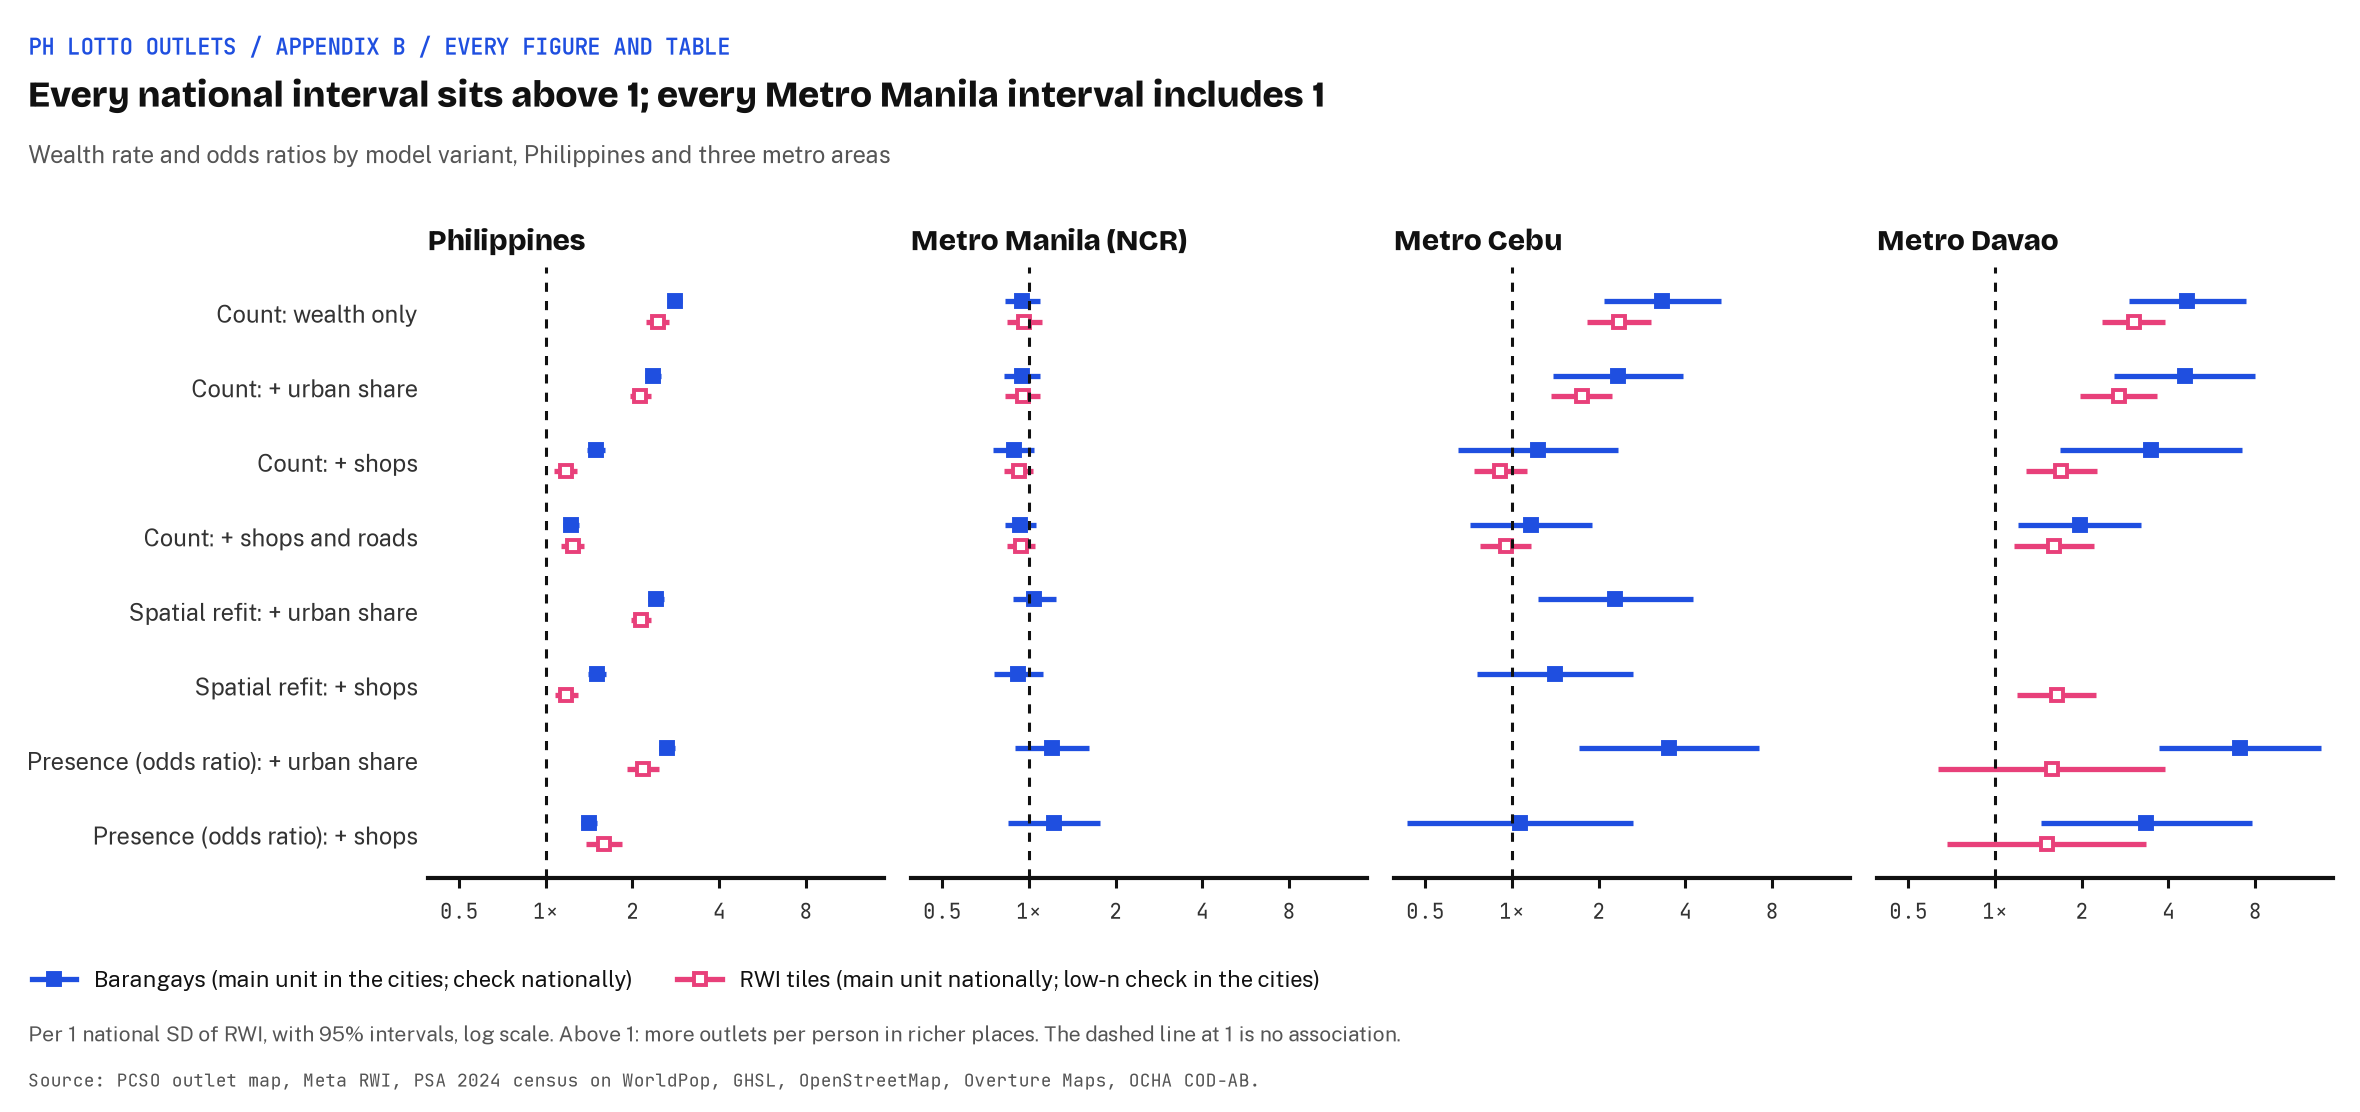

In [17]:
Image(charts.rate_ratio_chart(m), width=900)

**Reading.** The three cities do not share one pattern.

- **Metro Manila.** Flat in every variant: about 0.9 to 1.0, every interval across 1.
- **Metro Cebu.** Richer barangays have about twice as many outlets per person with urban share alone (2.34), but the gap goes with shops: with the shops control the ratio is 1.23 (0.65-2.33), and the tiles give 0.91, as flat as NCR.
- **Metro Davao.** Richer barangays have more outlets per person in every variant: 4.55 without shops, 3.47 with them, and 1.97 with shops and roads.

These numbers fit a between-place reading of the national gradient.
Metro Manila is urban throughout, with a narrow wealth range.
Metro Davao spans a wide urban and rural range inside one boundary: Davao City's uplands, the southern municipalities and the island of Samal sit beside its urban core.
Metro Cebu falls between the two.
Urban share is in every model, but it is near 1 for most of the richer half of each city, so it cannot tell a town centre from a suburb.
The tables describe where outlets are; they do not say why.
The paper's Discussion section (docs/paper.md) takes up what this does and does not say about the "tax on the poor" claim.